# PA2 Task 1 - Direct Preference Optimization (Kaggle, also runs on Colab)

**The setup.** One frozen reference model (Qwen2.5-1.5B-Instruct) and a trainable LoRA adapter on top of
it. DPO only ever sees fixed (prompt, chosen, rejected) pairs: no generation during training, no reward
model in the loss. The question is not just "does preference accuracy go up?", but **what did the model
learn to prefer**: better content, or simply longer answers?

| Run | Training data | Budget | beta | Trained here? |
|---|---|---|---|---|
| `sft` | none | none | none | **no**: the untouched base model, evaluated as the reference row |
| `standard` | full standard train set | 1 epoch | 0.10 | yes (Task 4 reuses this adapter) |
| `beta_0.03`, `beta_0.1`, `beta_0.3` | first 600 standard pairs | short | each | yes |
| `length_balanced` | supplied length-balanced set | 1 epoch | 0.10 | yes |
| `smoke` | 64 pairs | 4 steps | 0.10 | pipeline test only, **never reported** |

**Three rules this notebook enforces**
1. **The bug fix is proven before any training.** T5 compares the starter loss, the fixed loss and a
   hand calculation, and stops the notebook if `dpo.py` still has the starter bug.
2. **One evaluation protocol for every condition.** Same 200 held-out prompts, same 10 word-limit prompts,
   same seed reset before generation, same decoding settings and 256-token cap. T12 and T13 check this
   from the saved files rather than assuming it.
3. **Nothing is chosen by looking at held-out results.** The main model stays beta = 0.10 whatever the
   sweep shows; Task 4 uses `standard`, never a fork.

**Inputs (Kaggle)**
- Settings -> **Accelerator: GPU T4 x2** (the scripts use one GPU; avoid P100, where the 8-bit reward model can fail).
- Settings -> **Internet: ON** (needs a phone-verified account). Course assets and models download at runtime.
- **Add Input -> dataset `pa2-task1`**: upload `pa2-task1.zip` (the fixed `task1_dpo/` files). Not needed
  if `REPO_URL` in T1 points at your own GitHub repo that already contains them.
- *(Resuming only)* add the **output of a previous version** of this notebook as an input. T1 copies its
  finished adapters and results back in, so finished runs are skipped.

**Timing on a T4 (rough; T9 prints a real estimate from your own GPU):** setup and checks 25 min,
standard training about 2 h, each evaluation 25-40 min, beta sweep about 2.5 h including evaluations,
length study about 2.5 h. That is about 8-10 h in total, under Kaggle's 12 h limit, but close. If T9's
estimate exceeds about 11 h, set `RUN_PARTS` in T1 to split the work across two commits.

Use **Save Version -> Save & Run All (Commit)** so a closed tab cannot kill the run. Everything worth
keeping is written to `/kaggle/working/outputs/` as it is produced.

**How to read the output.** Every check prints three lines:
`PASS / FAIL / OBSERVE`, the **expected** result, and the **actual** result. `OBSERVE` means there is no
right answer: it is a finding for your report, and the expected line states the hypothesis being tested.

## Part A - setup

In [1]:
# T1. Assemble the repo, connect the saved output folder, and layer in the fixed Task 1 files.
# Nothing here imports torch/transformers, so T2's pip install can change versions safely.
import os, sys, glob, json, math, shutil, subprocess, time, zipfile
from pathlib import Path

ON_KAGGLE = os.path.exists('/kaggle/working')
REPO_URL  = 'https://github.com/AbDu11aHHH/ATML-PA2-LLM-PostTraining.git'   # <- or YOUR repo with the fixed task1_dpo/
REPO      = '/tmp/PA2'           # scratch copy: course assets are big and must NOT be saved as notebook output
GEN_PROMPTS = 200                # held-out prompts generated per condition; identical for every condition
SMOKE_PAIRS = 64                 # 64 pairs / batch 2 / grad-accum 8 = 4 optimizer steps
RUN_PARTS   = {'C_standard': True, 'D_beta': True, 'E_length': True}   # set False to split across commits

if ON_KAGGLE:
    OUT, BASE = '/kaggle/working/outputs', '/kaggle/input'
    os.environ['HF_HOME'] = '/tmp/hf'                       # model cache on fast local disk, not saved
else:                                                        # Colab: keep outputs on Drive
    from google.colab import drive; drive.mount('/content/drive')
    OUT  = '/content/drive/MyDrive/ATML_PA2/task1_outputs'
    BASE = '/content/drive/MyDrive/ATML_PA2/inputs'          # put the unzipped pa2-task1/ folder here
    os.environ['HF_HOME'] = '/content/hf'
for sub in ['outputs', 'results']:
    os.makedirs(f'{OUT}/{sub}', exist_ok=True)

CHECKS = []
def expect(name, expected, actual, ok):
    """ok=True -> PASS, ok=False -> FAIL, ok=None -> OBSERVE (a finding, not a test)."""
    tag = {True: 'PASS   ', False: 'FAIL   ', None: 'OBSERVE'}[ok]
    print(f'[{tag}] {name}\n            expected: {expected}\n            actual  : {actual}')
    CHECKS.append((tag.strip(), name))

def run(cmd):
    print('$', cmd, flush=True)
    p = subprocess.Popen(cmd, shell=True, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end='')
    if p.wait() != 0:
        raise RuntimeError(f'Command failed (exit code {p.returncode}): {cmd}')

# 1. clone the starter (or your) repo
if not os.path.isdir(f'{REPO}/.git'):
    subprocess.run(f'git clone -q {REPO_URL} {REPO}', shell=True, check=True)
os.chdir(REPO); sys.path.insert(0, REPO)
print('  cloned      :', REPO_URL)

# 2. layer the fixed task1_dpo files over the starter versions
FILES = ['dpo.py', 'train.py', 'evaluate.py', 'ablate_beta.py', 'analyze_length.py']
FIX_MARK = 'margin = policy_margin - ref_margin'
hits = [p for p in glob.glob(f'{BASE}/**/dpo.py', recursive=True) if FIX_MARK in open(p).read()]
if hits:
    src_dir = os.path.dirname(hits[0])
    for f in FILES:
        shutil.copy(f'{src_dir}/{f}', f'{REPO}/task1_dpo/{f}')
    print('  layered in  :', src_dir)
else:
    print('  layered in  : nothing found under', BASE, '-> using the repo copy as-is')

# 3. point repo/outputs and repo/results at the SAVED folder, so adapters + logs survive the session
for sub in ['outputs', 'results']:
    local = Path(REPO, sub)
    if local.is_symlink():
        continue
    if local.exists():
        shutil.copytree(local, f'{OUT}/{sub}', dirs_exist_ok=True); shutil.rmtree(local)
    local.symlink_to(f'{OUT}/{sub}', target_is_directory=True)

# 4. resume: copy finished work from an attached previous notebook version (Kaggle)
if ON_KAGGLE:
    for kind in ['outputs', 'results']:
        for prev in glob.glob(f'{BASE}/**/{kind}/task1_dpo', recursive=True):
            shutil.copytree(prev, f'{OUT}/{kind}/task1_dpo', dirs_exist_ok=True)
            print(f'  resumed     : {prev}')

src = {f: open(f'task1_dpo/{f}').read() for f in FILES}
expect('dpo.py carries the bug fix', f'the line `{FIX_MARK}`', 'found' if FIX_MARK in src['dpo.py'] else 'NOT found (starter code?)', FIX_MARK in src['dpo.py'])
expect('train/evaluate/ablate/analyze are implemented', 'no NotImplementedError left in any of the 4 files',
       [f for f in FILES[1:] if 'NotImplementedError' in src[f]] or 'none left', not any('NotImplementedError' in src[f] for f in FILES[1:]))
latest = 'stratified_preference' in src['analyze_length.py'] and 'filter_fitting' in src['train.py'] and 'filter_fitting' in src['evaluate.py']
expect('latest file versions', 'length study on the common prompts + the shared too-long-prompt filter (filter_fitting)',
       'yes' if latest else 'OLD version -- upload the newest pa2-task1.zip as a new dataset version', latest)
done = sorted(p.parent.name for p in Path(f'{OUT}/outputs/task1_dpo').glob('*/adapter_config.json'))
print(f'\n  repo    : {REPO}\n  outputs : {OUT}\n  adapters already trained (will be skipped): {done or "none"}')
assert FIX_MARK in src['dpo.py'] and latest, 'Attach the pa2-task1 dataset (or set REPO_URL to your repo) before continuing.' 

  cloned      : https://github.com/AbDu11aHHH/ATML-PA2-LLM-PostTraining.git
  layered in  : /kaggle/input/datasets/zylah628/pa2-task1/pa2-task1 (1)
[PASS   ] dpo.py carries the bug fix
            expected: the line `margin = policy_margin - ref_margin`
            actual  : found
[PASS   ] train/evaluate/ablate/analyze are implemented
            expected: no NotImplementedError left in any of the 4 files
            actual  : none left
[PASS   ] latest file versions
            expected: length study on the common prompts + the shared too-long-prompt filter (filter_fitting)
            actual  : yes

  repo    : /tmp/PA2
  outputs : /kaggle/working/outputs
  adapters already trained (will be skipped): none


In [2]:
# T2. Install the pinned environment and fetch the fixed course assets (Internet must be ON).
run('pip install -q -r requirements.txt')
try:
    run('python -m scripts.download_assets')
except RuntimeError:
    print('\n  Download failed. On Kaggle: Settings -> Internet ON (phone-verified account needed).'); raise
run('python -m scripts.validate_assets')      # the manual: setup is complete when validation passes
run('python -m scripts.check_environment')
expect('course assets', 'download_assets + validate_assets exit 0', 'both exited 0', True)

import importlib.metadata as im
PINNED = {'transformers': '4.57.1', 'trl': '0.27.2', 'peft': '0.17.1', 'tokenizers': '0.22.1'}
ver = {}
for p in ['torch', 'transformers', 'trl', 'peft', 'tokenizers', 'bitsandbytes', 'accelerate']:
    try: ver[p] = im.version(p)
    except im.PackageNotFoundError: ver[p] = 'MISSING'
print('\n  ' + '\n  '.join(f'{k:13s} {v}' for k, v in ver.items()))
expect('pinned library versions', PINNED, {k: ver[k] for k in PINNED}, all(ver[k] == v for k, v in PINNED.items()))

$ pip install -q -r requirements.txt
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 116.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 65.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 530.9/530.9 kB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.9/504.9 kB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 27.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
$ 

In [3]:
# T3. Helpers. report_training() prints a health summary, saves the curves, and returns a verdict.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

LN2 = math.log(2)      # 0.6931 = DPO loss when every margin is 0, i.e. when policy == reference
RES = 'results/task1_dpo'
FIG = f'{RES}/figures'; os.makedirs(FIG, exist_ok=True)

def read_jsonl(p): return [json.loads(l) for l in open(p) if l.strip()]
def load_json(p):  return json.load(open(p))
def avg(rows, k):  return sum(r[k] for r in rows) / len(rows)
def clip(s, n=300):
    s = ' '.join(str(s).split()); return s if len(s) <= n else s[:n] + ' ...'

def report_training(run_name):
    """What to look for:
       loss         starts at exactly ln 2 = 0.6931 and must end BELOW it
       accuracy     training-batch fraction with margin > 0; starts at 0.0 (all margins exactly 0), then
                    should climb above 0.5 (coin flip)
       log-ratios   log pi_theta - log pi_ref for chosen and rejected separately; if BOTH go negative,
                    DPO made both responses less likely and only widened the gap between them
       grad norm    before clipping; occasional values > 1.0 are clipped and are normal; NaN/inf is not"""
    d = f'{RES}/{run_name}'
    log, s = read_jsonl(f'{d}/train_log.jsonl'), load_json(f'{d}/train_summary.json')
    k = max(1, len(log) // 10); first, last = log[:k], log[-k:]
    gn = [r['grad_norm'] for r in log]
    print(f'\n=== {run_name} ===')
    print(f'  data / beta / steps     : {s["num_pairs"]} pairs, beta = {s["beta"]}, {s["optimizer_steps"]} optimizer steps (effective batch {s["effective_batch"]})')
    print(f'  wall clock / peak VRAM  : {s["wall_clock_s"]/60:.1f} min, {s["peak_vram_gb"]:.2f} GB   [{s["precision"]}]')
    print(f'  loss                    : step 1 = {log[0]["loss"]:.4f} (expected {LN2:.4f}) -> last 10% = {avg(last, "loss"):.4f}')
    print(f'  train pref. accuracy    : first 10% = {avg(first, "preference_accuracy"):.3f} -> last 10% = {avg(last, "preference_accuracy"):.3f}   (0.5 = coin flip)')
    print(f'  mean margin m           : {avg(first, "margin_mean"):+.3f} -> {avg(last, "margin_mean"):+.3f}')
    c, r = avg(last, 'chosen_logratio_mean'), avg(last, 'rejected_logratio_mean')
    print(f'  log-ratio vs reference  : chosen {c:+.3f} | rejected {r:+.3f}   (last 10%)')
    print(f'  grad norm (pre-clip)    : median {np.median(gn):.3f}, max {max(gn):.3f}, clipped on {sum(g > 1.0 for g in gn)}/{len(gn)} steps')
    bad = any(not math.isfinite(x['loss']) or not math.isfinite(x['grad_norm']) for x in log)
    v = ('BROKEN (NaN/inf appeared)' if bad else
         'SUSPICIOUS START (step-1 loss != ln 2, so policy != reference at init)' if abs(log[0]['loss'] - LN2) > 0.01 else
         'NOT LEARNING (loss still ~ ln 2)' if avg(last, 'loss') > LN2 - 0.01 else 'LEARNING')
    print(f'  VERDICT: {v}')
    if c < 0 and r < 0:
        print('  note: BOTH log-ratios are negative -> chosen AND rejected got less likely than under the reference;\n'
              '        only the GAP widened. This is known DPO behaviour and worth one sentence in the report.')
    elif c > 0 > r:
        print('  note: chosen up, rejected down -- the textbook picture.')
    steps = [x['opt_step'] for x in log]; w = max(1, len(log) // 25)
    sm = lambda key: pd.Series([x[key] for x in log]).rolling(w, min_periods=1).mean()
    panels = [('loss', 'DPO loss', LN2), ('preference_accuracy', 'train pref. accuracy', 0.5),
              ('margin_mean', 'mean margin m', 0), ('grad_norm', 'grad norm (pre-clip)', 1.0)]
    fig, axes = plt.subplots(1, 5, figsize=(18, 3))
    for ax, (key, title, line) in zip(axes, panels):
        ax.plot(steps, sm(key)); ax.axhline(line, color='r', ls=':', lw=1)
        ax.set_title(f'{run_name}: {title}', fontsize=9); ax.set_xlabel('optimizer step'); ax.grid(alpha=.3)
    axes[4].plot(steps, sm('chosen_logratio_mean'), label='chosen'); axes[4].plot(steps, sm('rejected_logratio_mean'), label='rejected')
    axes[4].axhline(0, color='r', ls=':', lw=1); axes[4].legend(fontsize=8); axes[4].grid(alpha=.3)
    axes[4].set_title(f'{run_name}: log pi_theta - log pi_ref', fontsize=9); axes[4].set_xlabel('optimizer step')
    fig.tight_layout(); fig.savefig(f'{FIG}/curves_{run_name}.png', dpi=140); plt.show(); plt.close(fig)
    return v, s

def metrics_row(name, budget=''):
    m = load_json(f'{RES}/{name}/metrics.json'); p, g, w = m['preference'], m['generation'], m['word_limit']
    return {'condition': name, 'budget': budget, 'beta': m['beta'],
            'pref_acc': p['preference_accuracy'], 'margin': p['margin_mean'], 'dpo_loss': p['dpo_loss'],
            'kl_token': g['kl_token_mean'], 'kl_seq': g['kl_seq_sum_mean'], 'reward': g['reward_mean'],
            'reward_std': g['reward_std'], 'len_mean': g['length_tokens']['mean'], 'len_std': g['length_tokens']['std'],
            'len_iqr': g['length_tokens']['iqr'], 'trunc_rate': g['truncation_rate'],
            'wl_compliance': w['word_limit_compliance'], 'wl_mean_words': w['mean_words'], 'gen_prompts': m['gen_prompts']}

def has_adapter(name): return os.path.exists(f'outputs/task1_dpo/{name}/adapter_config.json')
def has_metrics(name): return os.path.exists(f'{RES}/{name}/metrics.json')
print('Helpers ready.  results ->', os.path.realpath(RES))

Helpers ready.  results -> /kaggle/working/outputs/results/task1_dpo


In [4]:
# T4. GPU and data check. Everything Task 1 reads is inspected BEFORE any GPU time is spent.
import torch
from collections import Counter
from common.data import load_yaml, prompt_messages, prompt_messages_from_preference, preference_responses
from common.data import read_jsonl as rj
from common.metrics import parse_word_limit
from common.models import load_tokenizer

gpu = torch.cuda.is_available()
expect('GPU present', 'a CUDA GPU (Kaggle: Accelerator = GPU T4 x2)', torch.cuda.get_device_name(0) if gpu else 'NONE', gpu)
assert gpu, 'No GPU -- set the accelerator and restart.'
mem = torch.cuda.get_device_properties(0).total_memory / 1e9
expect('GPU memory', '>= 14.5 GB (T4 = 15.8 GB)', f'{mem:.1f} GB on {torch.cuda.device_count()} device(s); scripts use cuda:0', mem >= 14.5)
expect('bf16 support', 'irrelevant here: configs say float16, so training uses fp16 + GradScaler either way (a T4 reports True only through slow emulation)', torch.cuda.is_bf16_supported(), None)
if 'P100' in torch.cuda.get_device_name(0):
    print('  WARNING: P100 detected. bitsandbytes 8-bit (the reward model) can fail here; switch to T4.')

cfg = load_yaml('configs/dpo.yaml'); P = cfg['paths']
D = {k: rj(P[k]) for k in ['dpo_standard_train', 'dpo_standard_eval', 'dpo_length_train', 'dpo_length_eval', 'word_limit_prompts']}
print()
for k, rows in D.items():
    print(f'  {k:20s} {len(rows):6d} rows | fields: {sorted(rows[0])}')
expect('all five Task 1 files load', '> 0 rows each', {k: len(v) for k, v in D.items()}, all(len(v) > 0 for v in D.values()))

ex = D['dpo_standard_train'][0]; yc, yr = preference_responses(ex)
print('\n  train row 0 (what one preference pair looks like):')
print('    PROMPT  :', clip(prompt_messages_from_preference(ex)[-1]['content'], 200))
print('    CHOSEN  :', clip(yc, 200)); print('    REJECTED:', clip(yr, 200))

lims = [parse_word_limit(prompt_messages(r)[-1]['content']) for r in D['word_limit_prompts']]
expect('word limit parses from every word-limit prompt', f'{len(lims)} / {len(lims)} parsed', f'{sum(l is not None for l in lims)} / {len(lims)}: {lims}', all(l is not None for l in lims))

from task1_dpo.analyze_length import STRATUM_KEYS, find_stratum_key
for k in ['dpo_length_train', 'dpo_length_eval']:
    try:
        key = find_stratum_key(D[k][0]); cnt = Counter(str(r[key]) for r in D[k])
        expect(f'{k}: three equal strata', 'exactly 3 strata with equal counts (the manual: equal numbers from each)',
               f'field "{key}": {dict(cnt)}', len(cnt) == 3 and max(cnt.values()) - min(cnt.values()) <= max(1, 0.05 * max(cnt.values())))
    except KeyError as e:
        expect(f'{k}: stratum field', f'one of {STRATUM_KEYS}', str(e), False if k == 'dpo_length_eval' else None)

tok = load_tokenizer(cfg['base_model']); L = int(cfg['max_sequence_length'])
def token_lengths(rows):
    out = []
    for r in rows:
        pm = prompt_messages_from_preference(r); c, j = preference_responses(r)
        out.append((len(tok.apply_chat_template(pm, tokenize=True, add_generation_prompt=True)),
                    len(tok(c, add_special_tokens=False)['input_ids']), len(tok(j, add_special_tokens=False)['input_ids'])))
    return np.array(out)
from task1_dpo.train import filter_fitting, MIN_RESPONSE_TOKENS
LENS, KEPT = {}, {}
print()
for k in ['dpo_standard_train', 'dpo_standard_eval', 'dpo_length_train', 'dpo_length_eval']:
    a = LENS[k] = token_lengths(D[k]); kept, kept_idx, dropped = filter_fitting(D[k], tok, L); KEPT[k] = kept
    expect(f'{k}: pairs dropped (prompt leaves < {MIN_RESPONSE_TOKENS} response tokens of {L})',
           'a few %; the SAME rule is applied in training and evaluation, and dropped IDs are saved (state this in the report)',
           f'{len(dropped)} of {len(D[k])} dropped ({len(dropped) / len(D[k]):.1%}); {int((a[:, 0] >= L).sum())} of them would have crashed training outright', None)
    print(f'            tokens (median): prompt {np.median(a[:,0]):.0f} | chosen {np.median(a[:,1]):.0f} | rejected {np.median(a[:,2]):.0f}'
          f' | cut to fit {L}: chosen {((a[:,0]+a[:,1]+1) > L).mean():.1%}, rejected {((a[:,0]+a[:,2]+1) > L).mean():.1%}')
a = LENS['dpo_standard_train']
expect('DATASET property: chosen longer than rejected (standard train)', 'no right answer; > 50% means the preference data itself rewards length',
       f'{(a[:,1] > a[:,2]).mean():.1%} of pairs, mean difference {np.mean(a[:,1] - a[:,2]):+.1f} tokens', None)

B, A = int(cfg['batch_size']), int(cfg['grad_accum_steps'])
STEPS = lambda n: math.ceil(math.ceil(n / B) / A)
N_STD, N_BAL, N_SHORT, N_EVAL = len(KEPT['dpo_standard_train']), len(KEPT['dpo_length_train']), int(cfg['short_ablation_examples']), len(KEPT['dpo_standard_eval'])
print(f'\n  length-eval strata AFTER filtering: {dict(Counter(str(r["length_stratum"]) for r in KEPT["dpo_length_eval"]))}  (per-stratum n is reported in T13)')
print(f'\n  standard        : {N_STD} pairs -> {math.ceil(N_STD/B)} micro-batches of {B} -> {STEPS(N_STD)} optimizer steps (effective batch {B*A})')
print(f'  each beta fork  : {N_SHORT} pairs -> {STEPS(N_SHORT)} optimizer steps')
print(f'  length-balanced : {N_BAL} pairs -> {STEPS(N_BAL)} optimizer steps')

[PASS   ] GPU present
            expected: a CUDA GPU (Kaggle: Accelerator = GPU T4 x2)
            actual  : Tesla T4
[PASS   ] GPU memory
            expected: >= 14.5 GB (T4 = 15.8 GB)
            actual  : 15.6 GB on 2 device(s); scripts use cuda:0
[OBSERVE] bf16 support
            expected: irrelevant here: configs say float16, so training uses fp16 + GradScaler either way (a T4 reports True only through slow emulation)
            actual  : True

  dpo_standard_train     1500 rows | fields: ['chosen', 'prompt', 'prompt_id', 'rejected', 'score_chosen', 'score_rejected', 'source_index', 'source_split']
  dpo_standard_eval       300 rows | fields: ['chosen', 'prompt', 'prompt_id', 'rejected', 'score_chosen', 'score_rejected', 'source_index', 'source_split']
  dpo_length_train       1500 rows | fields: ['chosen', 'chosen_tokens', 'length_difference', 'length_stratum', 'prompt', 'prompt_id', 'rejected', 'rejected_tokens', 'score_chosen', 'score_rejected', 'source_index', 'source_spl

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]


[OBSERVE] dpo_standard_train: pairs dropped (prompt leaves < 64 response tokens of 768)
            expected: a few %; the SAME rule is applied in training and evaluation, and dropped IDs are saved (state this in the report)
            actual  : 57 of 1500 dropped (3.8%); 54 of them would have crashed training outright
            tokens (median): prompt 111 | chosen 236 | rejected 175 | cut to fit 768: chosen 15.1%, rejected 12.5%
[OBSERVE] dpo_standard_eval: pairs dropped (prompt leaves < 64 response tokens of 768)
            expected: a few %; the SAME rule is applied in training and evaluation, and dropped IDs are saved (state this in the report)
            actual  : 11 of 300 dropped (3.7%); 10 of them would have crashed training outright
            tokens (median): prompt 100 | chosen 192 | rejected 172 | cut to fit 768: chosen 15.3%, rejected 13.7%
[OBSERVE] dpo_length_train: pairs dropped (prompt leaves < 64 response tokens of 768)
            expected: a few %; the SAME r

## Part B - prove the pipeline before spending GPU hours

T5-T7 test the loss, the masking and the reference model in isolation. T8-T9 run the real scripts on a tiny budget. Each FAIL here is cheaper to fix now than after a 2 h run.

In [5]:
# T5. Unit test: starter (buggy) loss vs fixed loss vs a hand calculation from the manual's equation.
# Runs on CPU. If the fixed loss disagrees with the hand calculation, the notebook stops here.
import torch.nn.functional as F
from task1_dpo.dpo import dpo_loss

def starter_loss(pc, pr, rc, rr, beta):          # exactly what the released starter computed
    return float(-F.logsigmoid(beta * ((pc - pr) + (rc - rr))).mean())
def by_hand(pc, pr, rc, rr, beta):               # the manual: m = [pc - rc] - [pr - rr]; L = log(1 + e^(-beta m))
    m = (pc - rc) - (pr - rr); return math.log(1 + math.exp(-beta * m)), m
T = lambda x: torch.tensor([float(x)])

print('Case A: policy prefers chosen by 2 nats, the reference already preferred it by 0.5, beta = 0.1')
pc, pr, rc, rr, b = -10, -12, -11, -11.5, 0.1
hand, m = by_hand(pc, pr, rc, rr, b); fixed = float(dpo_loss(T(pc), T(pr), T(rc), T(rr), b)[0]); buggy = starter_loss(T(pc), T(pr), T(rc), T(rr), b)
print(f'   by hand: m = (pc - rc) - (pr - rr) = ({pc} - {rc}) - ({pr} - {rr}) = {m}  ->  loss = log(1 + e^-{b*m:.2f}) = {hand:.4f}')
expect('fixed loss == hand calculation', f'{hand:.4f}', f'{fixed:.4f}', abs(fixed - hand) < 1e-5)
expect('starter loss differs', f'!= {hand:.4f} (it ADDS the reference margin: m_starter = 2 + 0.5 = 2.5)', f'{buggy:.4f}', abs(buggy - hand) > 1e-3)

print('\nCase B: policy == reference (the situation at step 1, before any training)')
pc = rc = -20.0; pr = rr = -15.0
for b in [0.03, 0.10, 0.30]:
    fixed = float(dpo_loss(T(pc), T(pr), T(rc), T(rr), b)[0]); buggy = starter_loss(T(pc), T(pr), T(rc), T(rr), b)
    expect(f'beta = {b}: loss with no training', f'ln 2 = {LN2:.4f} for ANY beta (margin is 0)', f'fixed {fixed:.4f} | starter {buggy:.4f}', abs(fixed - LN2) < 1e-5)
print('   -> the starter is NOT ln 2 before training: it treats the reference\'s own opinion as if the policy had learned it.')

g = torch.Generator().manual_seed(0)
x = [torch.randn(64, generator=g) * 20 - 100 for _ in range(4)]
fixed = float(dpo_loss(*x, 0.1)[0]); hand = float(torch.log1p(torch.exp(-0.1 * ((x[0] - x[2]) - (x[1] - x[3])))).mean())
expect('batch of 64 random pairs: fixed vs hand formula', '|difference| < 1e-5', f'{abs(fixed - hand):.2e}', abs(fixed - hand) < 1e-5)
assert all(t != 'FAIL' for t, n in CHECKS if n.startswith(('fixed', 'beta =', 'batch'))), 'dpo.py does not match the manual -- stop.' 

Case A: policy prefers chosen by 2 nats, the reference already preferred it by 0.5, beta = 0.1
   by hand: m = (pc - rc) - (pr - rr) = (-10 - -11) - (-12 - -11.5) = 1.5  ->  loss = log(1 + e^-0.15) = 0.6210
[PASS   ] fixed loss == hand calculation
            expected: 0.6210
            actual  : 0.6210
[PASS   ] starter loss differs
            expected: != 0.6210 (it ADDS the reference margin: m_starter = 2 + 0.5 = 2.5)
            actual  : 0.5759

Case B: policy == reference (the situation at step 1, before any training)
[PASS   ] beta = 0.03: loss with no training
            expected: ln 2 = 0.6931 for ANY beta (margin is 0)
            actual  : fixed 0.6931 | starter 0.8544
[PASS   ] beta = 0.1: loss with no training
            expected: ln 2 = 0.6931 for ANY beta (margin is 0)
            actual  : fixed 0.6931 | starter 1.3133
[PASS   ] beta = 0.3: loss with no training
            expected: ln 2 = 0.6931 for ANY beta (margin is 0)
            actual  : fixed 0.6931 | start

In [6]:
# T6. Tokenisation and response-mask check (CPU). The loss must sum over RESPONSE tokens only.
from common.data import encode_prompt_response, pad_batch
row = D['dpo_standard_train'][0]; pm = prompt_messages_from_preference(row); yc, yr = preference_responses(row)
ids, rmask = encode_prompt_response(tok, pm, yc, L)
n_prompt = rmask.index(1); resp = [i for i, m in zip(ids, rmask) if m == 1]
tail = tok.decode(ids[n_prompt - 4:n_prompt])
expect('the prompt ends with the assistant header', "...'<|im_start|>assistant\\n'", repr(tail), tail.endswith('assistant\n'))
expect('mask is 0 on the prompt, 1 on the response', f'{n_prompt} zeros, then {len(ids) - n_prompt} ones', f'zeros = {rmask.count(0)}, ones = {rmask.count(1)}',
       rmask[:n_prompt] == [0] * n_prompt and rmask[n_prompt:] == [1] * (len(ids) - n_prompt))
expect('the last response token is EOS', repr(tok.eos_token), repr(tok.decode([resp[-1]])), resp[-1] == tok.eos_token_id)
dec = tok.decode(resp, skip_special_tokens=True)
expect('masked tokens decode back to the chosen response', repr(clip(yc, 70)), repr(clip(dec, 70)), ' '.join(dec.split())[:150] == ' '.join(yc.split())[:150])
b = pad_batch(tok, [encode_prompt_response(tok, pm, yc, L), encode_prompt_response(tok, pm, yr, L)])
short = int(b['attention_mask'].sum(1).argmin())
expect('padding goes on the LEFT', 'attention mask of the shorter sequence starts with 0s', b['attention_mask'][short, :6].tolist(),
       b['attention_mask'][short, 0].item() == 0 or b['attention_mask'].sum(1).min() == b['attention_mask'].shape[1])

[PASS   ] the prompt ends with the assistant header
            expected: ...'<|im_start|>assistant\n'
            actual  : '\n<|im_start|>assistant\n'
[PASS   ] mask is 0 on the prompt, 1 on the response
            expected: 85 zeros, then 58 ones
            actual  : zeros = 85, ones = 58
[PASS   ] the last response token is EOS
            expected: '<|im_end|>'
            actual  : '<|im_end|>'
[PASS   ] masked tokens decode back to the chosen response
            expected: 'If Jim decreases the speed of water flowing out of his bathroom tap, t ...'
            actual  : 'If Jim decreases the speed of water flowing out of his bathroom tap, t ...'
[PASS   ] padding goes on the LEFT
            expected: attention mask of the shorter sequence starts with 0s
            actual  : [0, 0, 0, 0, 0, 0]


In [7]:
# T7. Reference-policy check on GPU. pi_ref = the same model with the LoRA adapter switched OFF.
#   (a) a fresh LoRA adapter must be a no-op (its B matrix starts at zero), so policy == reference exactly
#   (b) after perturbing the adapter, the POLICY must change while the REFERENCE must not, which proves
#       reference_mode() really switches the adapter off (otherwise (a) would pass trivially)
from common.models import load_policy, reference_mode, clear_gpu
from common.generation import response_sequence_logprobs
model = load_policy(cfg, trainable=True, fresh_lora=True); model.eval()
batch = {k: v.cuda() for k, v in b.items()}
with torch.no_grad():
    pol, _, m = response_sequence_logprobs(model, batch)
    with reference_mode(model):
        ref, _, _ = response_sequence_logprobs(model, batch)
    expect('(a) fresh adapter: policy == reference', 'max |log pi_theta - log pi_ref| = 0', f'{(pol - ref).abs().max().item():.2e}', (pol - ref).abs().max().item() < 1e-3)
    expect('sequence log-probs: negative sums over response tokens', '< 0, roughly -0.1 to -3 nats per token',
           f'chosen {pol[0]:.1f} ({pol[0] / m[0].sum():.2f}/token), rejected {pol[1]:.1f} ({pol[1] / m[1].sum():.2f}/token)', bool((pol < 0).all()))
    expect('only response tokens are counted', f'{rmask.count(1)} tokens for the chosen response (from T6)', int(m.sum(1)[0]),
           int(m.sum(1)[0]) == rmask.count(1))
    for n_, p_ in model.named_parameters():
        if 'lora_B' in n_: p_.add_(torch.randn_like(p_) * 0.02)
    pol2, _, _ = response_sequence_logprobs(model, batch)
    with reference_mode(model):
        ref2, _, _ = response_sequence_logprobs(model, batch)
expect('(b) perturbed adapter: policy moves, reference does not', '|pol - ref| > 0  and  |ref_after - ref_before| = 0',
       f'|pol - ref| = {(pol2 - ref2).abs().max():.3f}, |ref_after - ref_before| = {(ref2 - ref).abs().max():.2e}',
       (pol2 - ref2).abs().max().item() > 1e-3 and (ref2 - ref).abs().max().item() < 1e-3)
del model, batch, pol, ref, pol2, ref2; clear_gpu()
print(f'\n  GPU memory still held by this notebook: {torch.cuda.memory_allocated() / 1e9:.2f} GB (training runs in a separate process)')

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[PASS   ] (a) fresh adapter: policy == reference
            expected: max |log pi_theta - log pi_ref| = 0
            actual  : 0.00e+00
[PASS   ] sequence log-probs: negative sums over response tokens
            expected: < 0, roughly -0.1 to -3 nats per token
            actual  : chosen -25.0 (-0.43/token), rejected -134.8 (-0.80/token)
[PASS   ] only response tokens are counted
            expected: 58 tokens for the chosen response (from T6)
            actual  : 58
[PASS   ] (b) perturbed adapter: policy moves, reference does not
            expected: |pol - ref| > 0  and  |ref_after - ref_before| = 0
            actual  : |pol - ref| = 5.701, |ref_after - ref_before| = 0.00e+00

  GPU memory still held by this notebook: 0.01 GB (training runs in a separate process)


In [8]:
# T8. Smoke-train: 64 pairs = 4 optimizer steps (about 3-5 min). Tests the whole training script end to end
# and measures your GPU's speed for the time estimate. This run is never reported.
for d in ['outputs/task1_dpo/smoke', f'{RES}/smoke']:
    shutil.rmtree(d, ignore_errors=True)
run(f'python -m task1_dpo.train --config configs/dpo.yaml --run-name smoke --max-examples {SMOKE_PAIRS} --output outputs/task1_dpo/smoke')
log, summ = read_jsonl(f'{RES}/smoke/train_log.jsonl'), load_json(f'{RES}/smoke/train_summary.json')
expect('adapter saved', 'outputs/task1_dpo/smoke/adapter_config.json exists', has_adapter('smoke'), has_adapter('smoke'))
expect('optimizer steps', STEPS(SMOKE_PAIRS), len(log), len(log) == STEPS(SMOKE_PAIRS))
expect('step-1 loss', f'ln 2 = {LN2:.4f} (the adapter starts as a no-op, so every margin is exactly 0)', f'{log[0]["loss"]:.4f}', abs(log[0]['loss'] - LN2) < 0.01)
expect('step-1 train accuracy', '0.0 (margins are exactly 0 and accuracy counts margin > 0)', log[0]['preference_accuracy'], log[0]['preference_accuracy'] < 0.05)
expect('gradient norms', 'finite and > 0 on every step', [round(r['grad_norm'], 3) for r in log], all(math.isfinite(r['grad_norm']) and r['grad_norm'] > 0 for r in log))
expect('loss after 4 steps', f'slightly below {LN2:.4f} (4 tiny steps, so this can be noisy)', [round(r['loss'], 4) for r in log], None)
expect('peak VRAM', f'< {mem:.1f} GB', f'{summ["peak_vram_gb"]:.2f} GB', summ['peak_vram_gb'] < mem)
SEC_PER_PAIR = summ['wall_clock_s'] / SMOKE_PAIRS
print(f'\n  speed: {SEC_PER_PAIR:.2f} s per training pair (includes warm-up, so slightly pessimistic)')

$ python -m task1_dpo.train --config configs/dpo.yaml --run-name smoke --max-examples 64 --output outputs/task1_dpo/smoke
[smoke] pairs=64 (dropped 57 too-long prompts) beta=0.1 micro-batches/epoch=32 optimizer steps=4 trainable params=1,089,536/1,544,803,840
[smoke] step 4/4 loss=0.6941 acc=0.312 margin=-0.020 gnorm=1.962
[smoke] done in 0.8 min, peak VRAM 7.63 GB -> /tmp/PA2/outputs/task1_dpo/smoke
[PASS   ] adapter saved
            expected: outputs/task1_dpo/smoke/adapter_config.json exists
            actual  : True
[PASS   ] optimizer steps
            expected: 4
            actual  : 4
[PASS   ] step-1 loss
            expected: ln 2 = 0.6931 (the adapter starts as a no-op, so every margin is exactly 0)
            actual  : 0.6931
[PASS   ] step-1 train accuracy
            expected: 0.0 (margins are exactly 0 and accuracy counts margin > 0)
            actual  : 0.0
[PASS   ] gradient norms
            expected: finite and > 0 on every step
            actual  : [2.222, 1.78

In [9]:
# T9. Smoke-evaluate the evaluation code on a tiny subset (16 pairs, 8 prompts), then estimate total time.
#   The SFT baseline is the reference itself, so its margin and KL must be 0 (up to float noise). This is a
#   built-in correctness test for the evaluation code.
import importlib, task1_dpo.evaluate as ev
importlib.reload(ev)
sub = D['dpo_standard_eval'][:16]
t0 = time.time(); m0, _ = ev.evaluate_adapter('configs/dpo.yaml', 'none', 'smoke_sft', pair_rows=sub, gen_prompts=8); t_eval = time.time() - t0
expect('SFT: held-out margin', '0 up to float noise (|m| < 1e-3): the policy IS the reference', f'{m0["preference"]["margin_mean"]:.2e}', abs(m0['preference']['margin_mean']) < 1e-3)
expect('SFT: KL from reference', '0 up to float noise (|KL| < 1e-4)', f'{m0["generation"]["kl_token_mean"]:.2e}', abs(m0['generation']['kl_token_mean']) < 1e-4)
expect('SFT: DPO loss', f'ln 2 = {LN2:.4f}', f'{m0["preference"]["dpo_loss"]:.4f}', abs(m0['preference']['dpo_loss'] - LN2) < 1e-4)
m1, _ = ev.evaluate_adapter('configs/dpo.yaml', 'outputs/task1_dpo/smoke', 'smoke_eval', pair_rows=sub, gen_prompts=8)
g1 = read_jsonl(f'{RES}/smoke_eval/generations.jsonl')
expect('smoke model: KL', '|KL| < 0.05 per token (4 tiny updates); a sampled estimate, so slightly negative is possible', f'{m1["generation"]["kl_token_mean"]:+.4f}', abs(m1['generation']['kl_token_mean']) < 0.05)
expect('generation lengths', f'every response <= {cfg["max_generation_tokens"]} tokens', f'max {max(g["length_tokens"] for g in g1)}', max(g['length_tokens'] for g in g1) <= cfg['max_generation_tokens'])
expect('reward-model scores', 'finite numbers (scale is arbitrary; only compare within Task 1)', [round(g['reward'], 2) for g in g1], all(math.isfinite(g['reward']) for g in g1))
expect('word-limit compliance', 'a fraction in [0, 1] over 10 prompts', m1['word_limit']['word_limit_compliance'], 0 <= (m1['word_limit']['word_limit_compliance'] or 0) <= 1)

# Time estimate. Generation dominates evaluation; teacher-forced pairs cost about 40% of a training pair.
t_gen = t_eval * (GEN_PROMPTS + 10) / (8 + 10)
eval_std = t_gen + 0.4 * SEC_PER_PAIR * N_EVAL
plan = [('standard train', SEC_PER_PAIR * N_STD), ('evaluate sft + standard', 2 * eval_std),
        ('3 beta forks: train', 3 * SEC_PER_PAIR * N_SHORT), ('3 beta forks: evaluate', 3 * eval_std),
        ('length-balanced train', SEC_PER_PAIR * N_BAL), ('length-balanced evaluate', eval_std),
        ('2 stratified pair passes', 2 * 0.4 * SEC_PER_PAIR * len(KEPT['dpo_length_eval']))]
print('\n  rough plan for THIS GPU:')
for k, s in plan: print(f'    {k:28s} {s / 3600:5.2f} h')
total = sum(s for _, s in plan) / 3600
expect('estimated total remaining time', '< 11 h to fit one Kaggle commit (12 h limit)', f'{total:.1f} h', total < 11)
if total >= 11: print('  -> split: commit 1 with RUN_PARTS D_beta/E_length = False; commit 2 attaching commit 1\'s output, C_standard = False.')
fails = [n for t, n in CHECKS if t == 'FAIL' and not n.startswith('estimated total')]
print('\nGATE: ' + ('all pipeline checks passed -- the long runs below are safe to start.' if not fails else f'{len(fails)} FAIL(s): {fails}'))
assert not fails, 'Stopping before the long runs: fix the FAIL(s) above first (in a commit this saves your GPU quota).' 

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

[smoke_sft] acc=0.000 loss=0.6931 KL=0.0000 reward=0.968 len=176.0 wl=0.4
[PASS   ] SFT: held-out margin
            expected: 0 up to float noise (|m| < 1e-3): the policy IS the reference
            actual  : 0.00e+00
[PASS   ] SFT: KL from reference
            expected: 0 up to float noise (|KL| < 1e-4)
            actual  : 0.00e+00
[PASS   ] SFT: DPO loss
            expected: ln 2 = 0.6931
            actual  : 0.6931
[smoke_eval] acc=0.625 loss=0.6900 KL=0.0000 reward=1.203 len=176.0 wl=0.4
[PASS   ] smoke model: KL
            expected: |KL| < 0.05 per token (4 tiny updates); a sampled estimate, so slightly negative is possible
            actual  : +0.0000
[PASS   ] generation lengths
            expected: every response <= 256 tokens
            actual  : max 256
[PASS   ] reward-model scores
            expected: finite numbers (scale is arbitrary; only compare within Task 1)
            actual  : [0.54, 3.7, 0.73, -0.96, 1.36, 1.26, 2.35, 0.65]
[PASS   ] word-limit complia

## Part C - standard DPO (about 2 h of training, then two evaluations)

**Before running, write down three predictions** (one line each, your own words). You will compare them
with what T11 prints, which is good material for the report:
1. Will held-out preference accuracy be well above 0.5, or only slightly above?
2. Will DPO responses be **longer** than SFT responses? (T4 told you whether the training data rewards length.)
3. Will word-limit compliance go up or down?

$ python -m task1_dpo.train --config configs/dpo.yaml --run-name standard
[standard] pairs=1443 (dropped 57 too-long prompts) beta=0.1 micro-batches/epoch=722 optimizer steps=91 trainable params=1,089,536/1,544,803,840
[standard] step 10/91 loss=0.6968 acc=0.375 margin=-0.072 gnorm=2.257
[standard] step 20/91 loss=0.6892 acc=0.688 margin=0.079 gnorm=2.136
[standard] step 30/91 loss=0.6916 acc=0.625 margin=0.032 gnorm=1.879
[standard] step 40/91 loss=0.6904 acc=0.625 margin=0.061 gnorm=1.548
[standard] step 50/91 loss=0.6922 acc=0.500 margin=0.029 gnorm=2.014
[standard] step 60/91 loss=0.6890 acc=0.750 margin=0.098 gnorm=1.892
[standard] step 70/91 loss=0.6819 acc=0.625 margin=0.254 gnorm=1.992
[standard] step 80/91 loss=0.6840 acc=0.688 margin=0.214 gnorm=2.149
[standard] step 90/91 loss=0.7279 acc=0.375 margin=-0.618 gnorm=2.814
[standard] step 91/91 loss=0.8204 acc=0.000 margin=-2.357 gnorm=8.774
[standard] done in 22.6 min, peak VRAM 7.63 GB -> /tmp/PA2/outputs/task1_dpo/standard

=

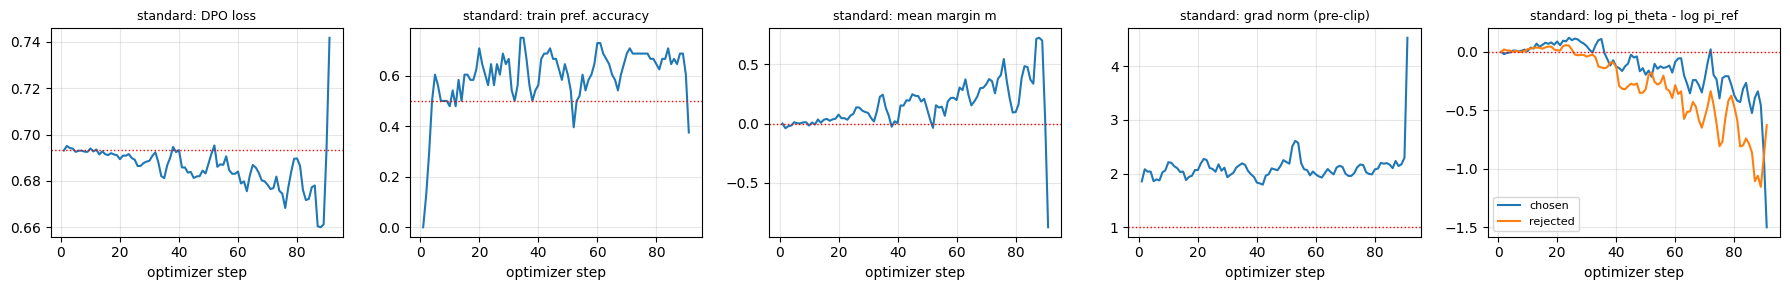

[PASS   ] standard: optimizer steps
            expected: 91
            actual  : 91
[FAIL   ] standard: training verdict
            expected: LEARNING (step-1 loss = ln 2, final loss below it, no NaN)
            actual  : BROKEN (NaN/inf appeared)


In [10]:
# T10. Standard DPO: one epoch on the full training set, beta = 0.10. Skipped if the adapter already exists.
if RUN_PARTS['C_standard'] and not has_adapter('standard'):
    run('python -m task1_dpo.train --config configs/dpo.yaml --run-name standard')
elif has_adapter('standard'):
    print('standard: adapter already exists -> skipping training (delete outputs/task1_dpo/standard to retrain)')
if has_adapter('standard'):
    v, s = report_training('standard')
    expect('standard: optimizer steps', STEPS(N_STD), s['optimizer_steps'], s['optimizer_steps'] == STEPS(N_STD))
    expect('standard: training verdict', 'LEARNING (step-1 loss = ln 2, final loss below it, no NaN)', v, v == 'LEARNING')

In [11]:
# T11. Evaluate SFT (reference row) and standard DPO under the common protocol.
for name, adapter in [('sft', 'none'), ('standard', 'outputs/task1_dpo/standard')]:
    if has_metrics(name):
        print(f'{name}: metrics already exist -> skipping')
    elif name == 'sft' or has_adapter('standard'):
        run(f'python -m task1_dpo.evaluate --config configs/dpo.yaml --adapter {adapter} --name {name} --gen-prompts {GEN_PROMPTS}')
if has_metrics('sft') and has_metrics('standard'):
    S, Dm = metrics_row('sft', 'none'), metrics_row('standard', '1 epoch')
    display(pd.DataFrame([S, Dm]).set_index('condition').round(4))
    expect('same protocol', f'both generated on {GEN_PROMPTS} prompts', f'sft {S["gen_prompts"]}, standard {Dm["gen_prompts"]}', S['gen_prompts'] == Dm['gen_prompts'] == GEN_PROMPTS)
    expect('SFT row (correctness test)', 'margin and KL = 0 up to float noise, by construction; report SFT accuracy as "n/a"', f'margin {S["margin"]:.2e}, KL {S["kl_token"]:.2e}', abs(S['margin']) < 1e-3 and abs(S['kl_token']) < 1e-4)
    expect('standard: held-out preference accuracy', '> 0.5 (better than a coin flip on UNSEEN pairs); typically 0.55-0.75 for a short LoRA run',
           f'{Dm["pref_acc"]:.3f}  (DPO loss {Dm["dpo_loss"]:.4f} vs ln 2 = {LN2:.4f})', Dm['pref_acc'] > 0.5)
    expect('standard: KL from reference', '> 0 (the trained policy rates its own samples higher than the reference does)', f'{Dm["kl_token"]:.4f} per token, {Dm["kl_seq"]:.2f} per response', Dm['kl_token'] > 0)
    expect('reward-model score: SFT -> DPO', 'hypothesis: higher. A gain is NOT proof of better answers -- check T14', f'{S["reward"]:+.3f} -> {Dm["reward"]:+.3f}', None)
    expect('response length: SFT -> DPO', 'hypothesis: longer, if DPO absorbed the data\'s length correlation', f'{S["len_mean"]:.1f} -> {Dm["len_mean"]:.1f} tokens (std {S["len_std"]:.1f} -> {Dm["len_std"]:.1f}); truncated {S["trunc_rate"]:.1%} -> {Dm["trunc_rate"]:.1%}', None)
    expect('word-limit compliance: SFT -> DPO', 'hypothesis: lower, if DPO learned verbosity', f'{S["wl_compliance"]:.0%} -> {Dm["wl_compliance"]:.0%} (mean words {S["wl_mean_words"]:.0f} -> {Dm["wl_mean_words"]:.0f})', None)

$ python -m task1_dpo.evaluate --config configs/dpo.yaml --adapter none --name sft --gen-prompts 200
[sft] acc=0.000 loss=0.6931 KL=0.0000 reward=1.247 len=162.0 wl=0.4
$ python -m task1_dpo.evaluate --config configs/dpo.yaml --adapter outputs/task1_dpo/standard --name standard --gen-prompts 200
[standard] acc=0.623 loss=0.6748 KL=0.0001 reward=1.236 len=161.7 wl=0.4


,budget,beta,pref_acc,margin,dpo_loss,kl_token,kl_seq,reward,reward_std,len_mean,len_std,len_iqr,trunc_rate,wl_compliance,wl_mean_words,gen_prompts
condition,,,,,,,,,,,,,,,,
sft,none,0.1,0.0000,0.0000,0.6931,0.0000,0.0000,1.2468,1.2146,161.990,104.7016,206.00,0.480,0.4,42.5,200
standard,1 epoch,0.1,0.6228,0.4294,0.6748,0.0001,0.0161,1.2362,1.2242,161.665,105.4052,215.25,0.485,0.4,44.6,200


[PASS   ] same protocol
            expected: both generated on 200 prompts
            actual  : sft 200, standard 200
[PASS   ] SFT row (correctness test)
            expected: margin and KL = 0 up to float noise, by construction; report SFT accuracy as "n/a"
            actual  : margin 0.00e+00, KL 0.00e+00
[PASS   ] standard: held-out preference accuracy
            expected: > 0.5 (better than a coin flip on UNSEEN pairs); typically 0.55-0.75 for a short LoRA run
            actual  : 0.623  (DPO loss 0.6748 vs ln 2 = 0.6931)
[PASS   ] standard: KL from reference
            expected: > 0 (the trained policy rates its own samples higher than the reference does)
            actual  : 0.0001 per token, 0.02 per response
[OBSERVE] reward-model score: SFT -> DPO
            expected: hypothesis: higher. A gain is NOT proof of better answers -- check T14
            actual  : +1.247 -> +1.236
[OBSERVE] response length: SFT -> DPO
            expected: hypothesis: longer, if DPO absorb

## Part D - beta study (three short runs from the original init)

**Prediction to write down first:** as beta goes 0.03 -> 0.10 -> 0.30, does KL go up or down? Why?

$ python -m task1_dpo.ablate_beta --config configs/dpo.yaml --skip-existing --gen-prompts 200
Required beta values: [0.03, 0.1, 0.3] | short-run examples per condition: 600
[beta_0.03] pairs=600 (dropped 57 too-long prompts) beta=0.03 micro-batches/epoch=300 optimizer steps=38 trainable params=1,089,536/1,544,803,840
[beta_0.03] step 10/38 loss=0.6916 acc=0.750 margin=0.107 gnorm=0.554
[beta_0.03] step 20/38 loss=0.6920 acc=0.625 margin=0.077 gnorm=0.593
[beta_0.03] step 30/38 loss=0.6964 acc=0.562 margin=-0.212 gnorm=0.687
[beta_0.03] step 38/38 loss=0.6886 acc=0.750 margin=0.305 gnorm=0.779
[beta_0.03] done in 9.2 min, peak VRAM 7.63 GB -> /tmp/PA2/outputs/task1_dpo/beta_0.03
[beta_0.03] acc=0.626 loss=0.6909 KL=-0.0002 reward=1.240 len=162.1 wl=0.4
[beta_0.1] pairs=600 (dropped 57 too-long prompts) beta=0.1 micro-batches/epoch=300 optimizer steps=38 trainable params=1,089,536/1,544,803,840
[beta_0.1] step 10/38 loss=0.6895 acc=0.688 margin=0.074 gnorm=1.840
[beta_0.1] step 20/38 los

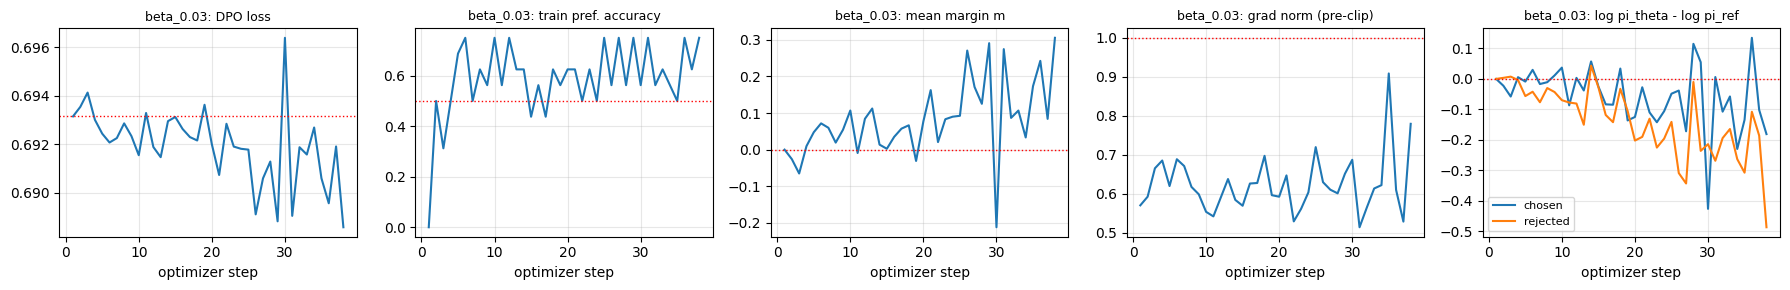


=== beta_0.1 ===
  data / beta / steps     : 600 pairs, beta = 0.1, 38 optimizer steps (effective batch 16)
  wall clock / peak VRAM  : 9.2 min, 7.63 GB   [fp16+GradScaler, fp32 LoRA]
  loss                    : step 1 = 0.6931 (expected 0.6931) -> last 10% = 0.6834
  train pref. accuracy    : first 10% = 0.146 -> last 10% = 0.771   (0.5 = coin flip)
  mean margin m           : -0.048 -> +0.201
  log-ratio vs reference  : chosen -0.043 | rejected -0.243   (last 10%)
  grad norm (pre-clip)    : median 2.027, max 3.052, clipped on 38/38 steps
  VERDICT: NOT LEARNING (loss still ~ ln 2)
  note: BOTH log-ratios are negative -> chosen AND rejected got less likely than under the reference;
        only the GAP widened. This is known DPO behaviour and worth one sentence in the report.


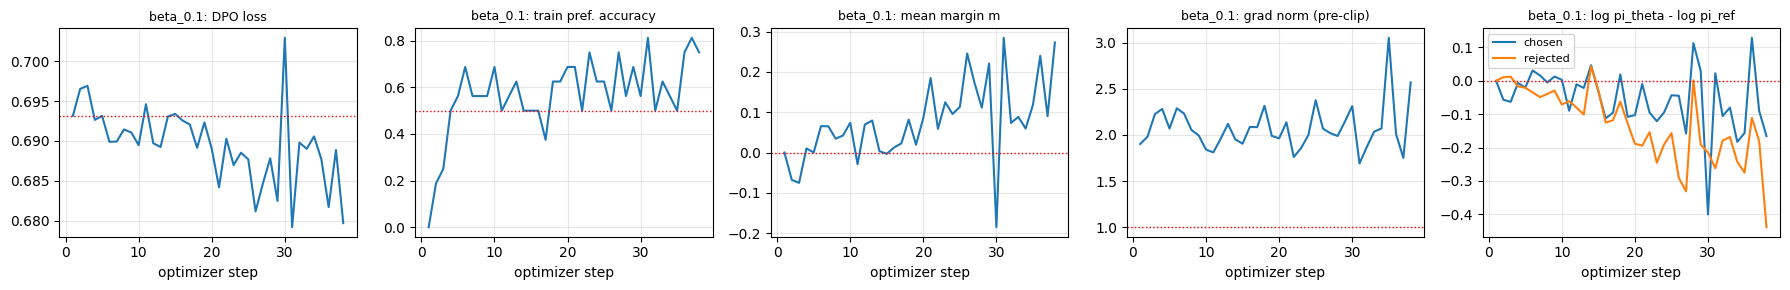


=== beta_0.3 ===
  data / beta / steps     : 600 pairs, beta = 0.3, 38 optimizer steps (effective batch 16)
  wall clock / peak VRAM  : 9.2 min, 7.63 GB   [fp16+GradScaler, fp32 LoRA]
  loss                    : step 1 = 0.6931 (expected 0.6931) -> last 10% = 0.6704
  train pref. accuracy    : first 10% = 0.271 -> last 10% = 0.792   (0.5 = coin flip)
  mean margin m           : -0.033 -> +0.166
  log-ratio vs reference  : chosen -0.068 | rejected -0.233   (last 10%)
  grad norm (pre-clip)    : median nan, max 9.153, clipped on 36/38 steps
  VERDICT: BROKEN (NaN/inf appeared)
  note: BOTH log-ratios are negative -> chosen AND rejected got less likely than under the reference;
        only the GAP widened. This is known DPO behaviour and worth one sentence in the report.


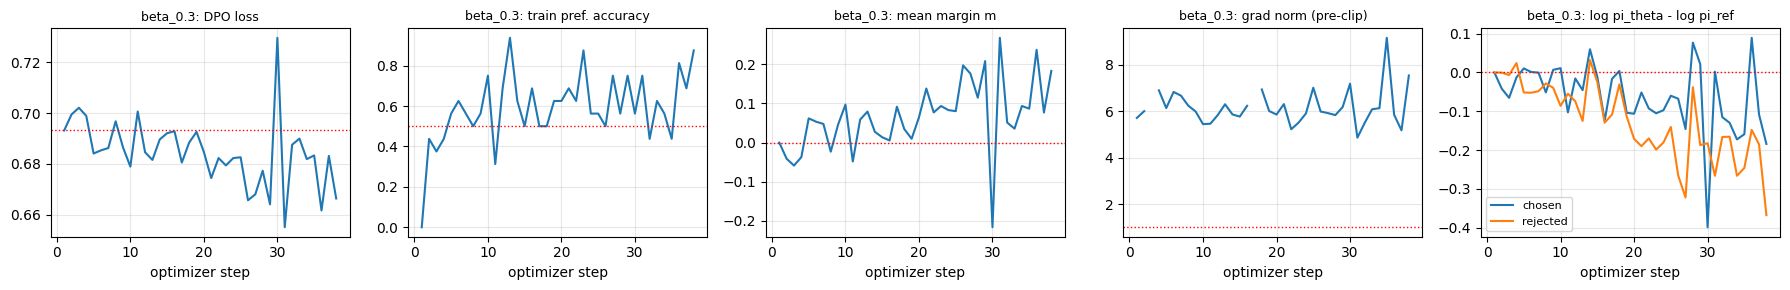

[PASS   ] controlled comparison (read from the saved files)
            expected: one identical value per setting across the 3 forks; only beta differs
            actual  : {'num_pairs': ['600'], 'seed': ['6304'], 'learning_rate': ['2e-05'], 'effective_batch': ['16'], 'optimizer_steps': ['38']}


,budget,beta,pref_acc,margin,kl_token,reward,len_mean,len_std,wl_compliance,gen_prompts
condition,,,,,,,,,,
beta_0.03,short (600 pairs),0.03,0.6263,0.1536,-0.0002,1.2401,162.090,105.9222,0.4,200
beta_0.1,short (600 pairs),0.10,0.6298,0.1467,-0.0001,1.2171,164.300,105.3103,0.4,200
beta_0.3,short (600 pairs),0.30,0.6263,0.1256,-0.0000,1.2976,160.625,104.6035,0.4,200
standard,1 epoch (different budget!),0.10,0.6228,0.4294,0.0001,1.2362,161.665,105.4052,0.4,200


[PASS   ] same generation protocol
            expected: 200 prompts for every row
            actual  : [200, 200, 200, 200]
[OBSERVE] kl_token as beta grows [0.03, 0.1, 0.3]
            expected: decreasing (larger beta saturates the sigmoid sooner -> less drift needed)
            actual  : [-0.0002, -0.0001, -0.0] -> increasing
[OBSERVE] margin as beta grows [0.03, 0.1, 0.3]
            expected: decreasing (with small beta the model must build a bigger margin to cut the loss)
            actual  : [0.1536, 0.1467, 0.1256] -> decreasing
[OBSERVE] pref_acc as beta grows [0.03, 0.1, 0.3]
            expected: unclear: accuracy only counts the SIGN of the margin
            actual  : [0.6263, 0.6298, 0.6263] -> NON-monotonic
[OBSERVE] reward as beta grows [0.03, 0.1, 0.3]
            expected: unclear
            actual  : [1.2401, 1.2171, 1.2976] -> NON-monotonic
[OBSERVE] len_mean as beta grows [0.03, 0.1, 0.3]
            expected: unclear
            actual  : [162.09, 164.3, 160.

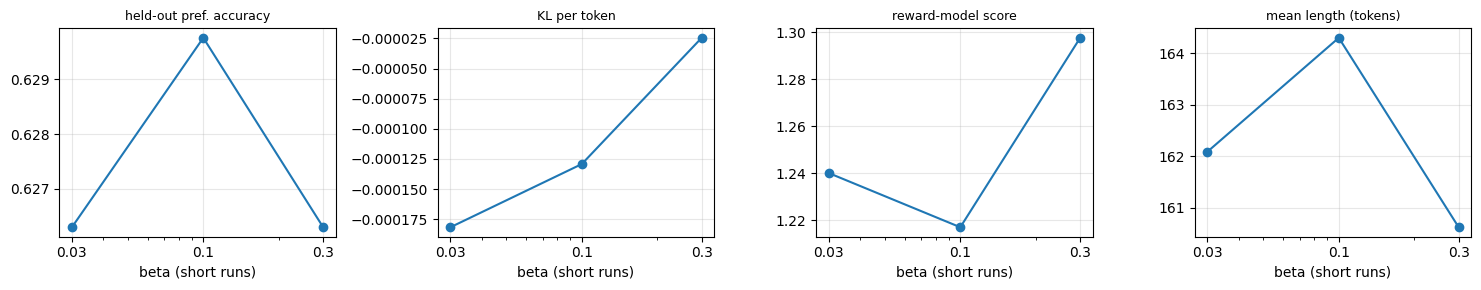

In [12]:
# T12. Regularisation-strength study: beta in {0.03, 0.10, 0.30}, each from the ORIGINAL init on the same
# 600 pairs with the same seed, optimiser and LoRA config. Only beta changes.
if RUN_PARTS['D_beta']:
    run(f'python -m task1_dpo.ablate_beta --config configs/dpo.yaml --skip-existing --gen-prompts {GEN_PROMPTS}')
BETAS = [float(x) for x in cfg['betas']]; names = [f'beta_{x:g}' for x in BETAS]
if all(has_metrics(n) for n in names):
    for n in names: report_training(n)
    ts = [load_json(f'{RES}/{n}/train_summary.json') for n in names]
    ctrl = {k: sorted({str(t[k]) for t in ts}) for k in ['num_pairs', 'seed', 'learning_rate', 'effective_batch', 'optimizer_steps']}
    expect('controlled comparison (read from the saved files)', 'one identical value per setting across the 3 forks; only beta differs', ctrl, all(len(v) == 1 for v in ctrl.values()))
    rows = [metrics_row(n, f'short ({N_SHORT} pairs)') for n in names]
    if has_metrics('standard'): rows.append(metrics_row('standard', '1 epoch (different budget!)'))
    tb = pd.DataFrame(rows).set_index('condition')
    display(tb[['budget', 'beta', 'pref_acc', 'margin', 'kl_token', 'reward', 'len_mean', 'len_std', 'wl_compliance', 'gen_prompts']].round(4))
    expect('same generation protocol', f'{GEN_PROMPTS} prompts for every row', list(tb['gen_prompts']), set(tb['gen_prompts']) == {GEN_PROMPTS})
    def trend(vals):
        d = np.diff(vals); return 'increasing' if (d > 0).all() else 'decreasing' if (d < 0).all() else 'NON-monotonic'
    short = tb.loc[names]
    hyp = {'kl_token': 'decreasing (larger beta saturates the sigmoid sooner -> less drift needed)',
           'margin': 'decreasing (with small beta the model must build a bigger margin to cut the loss)',
           'pref_acc': 'unclear: accuracy only counts the SIGN of the margin', 'reward': 'unclear', 'len_mean': 'unclear'}
    for k, h in hyp.items():
        t = trend(short[k].values)
        expect(f'{k} as beta grows {BETAS}', h, f'{[round(x, 4) for x in short[k]]} -> {t}', None)
    print('\n  Reminder for the report: held-out DPO LOSS is not comparable across beta (beta sits inside the loss).')
    fig, axes = plt.subplots(1, 4, figsize=(15, 3))
    for ax, (k, t) in zip(axes, [('pref_acc', 'held-out pref. accuracy'), ('kl_token', 'KL per token'), ('reward', 'reward-model score'), ('len_mean', 'mean length (tokens)')]):
        ax.plot(BETAS, short[k], marker='o'); ax.set_xscale('log'); ax.set_xticks(BETAS); ax.set_xticklabels([f'{x:g}' for x in BETAS])
        ax.set_title(t, fontsize=9); ax.set_xlabel('beta (short runs)'); ax.grid(alpha=.3)
    fig.tight_layout(); fig.savefig(f'{FIG}/beta_study.png', dpi=140); plt.show(); plt.close(fig)
    tb.to_csv(f'{RES}/beta_table.csv')

## Part E - length-confounding study

**Prediction to write down first:** on *rejected-longer* pairs, will the standard model do better or worse than on *preferred-longer* pairs? And the balanced model?

$ python -m task1_dpo.analyze_length --config configs/dpo.yaml --skip-existing --gen-prompts 200
Length-balanced train rows: 1500
Length-stratified eval rows: 246
[length_balanced] pairs=1432 (dropped 68 too-long prompts) beta=0.1 micro-batches/epoch=716 optimizer steps=90 trainable params=1,089,536/1,544,803,840
[length_balanced] step 10/90 loss=0.6930 acc=0.562 margin=0.004 gnorm=2.165
[length_balanced] step 20/90 loss=0.6813 acc=0.688 margin=0.241 gnorm=1.979
[length_balanced] step 30/90 loss=0.6910 acc=0.562 margin=0.046 gnorm=1.643
[length_balanced] step 40/90 loss=0.6763 acc=0.750 margin=0.393 gnorm=2.030
[length_balanced] step 50/90 loss=0.6881 acc=0.562 margin=0.156 gnorm=1.775
[length_balanced] step 60/90 loss=0.6824 acc=0.625 margin=0.240 gnorm=1.944
[length_balanced] step 70/90 loss=0.6744 acc=0.625 margin=0.434 gnorm=1.802
[length_balanced] step 80/90 loss=0.6813 acc=0.750 margin=0.354 gnorm=2.159
[length_balanced] step 90/90 loss=0.6250 acc=0.875 margin=1.461 gnorm=2.833
[

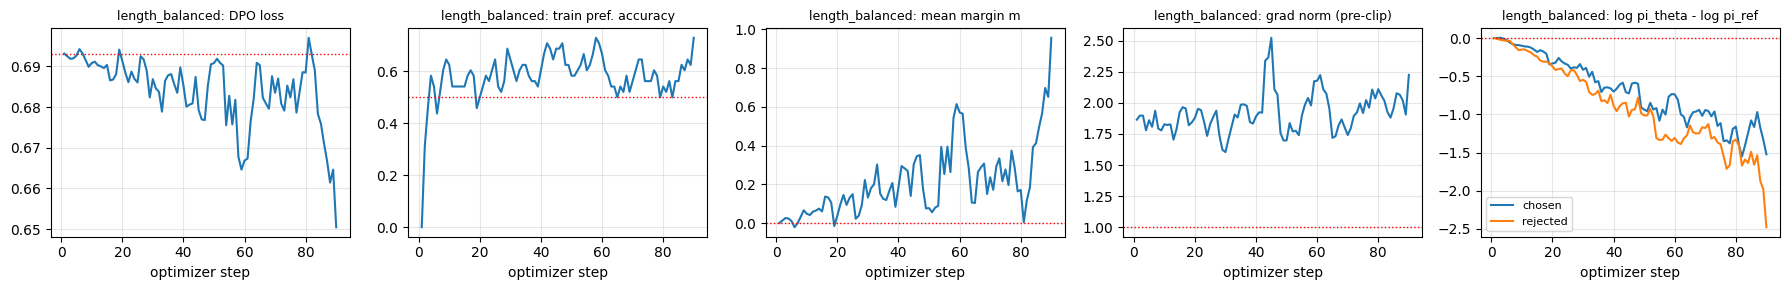

DATASET length structure (tokens; no model involved):


,n,frac_chosen_longer,frac_rejected_longer,mean_len_diff_chosen_minus_rejected,median_len_diff
standard_train,1500.0,0.563,0.422,42.450,18.0
balanced_train,1500.0,0.491,0.486,5.163,0.0
stratified_eval,246.0,0.484,0.500,2.695,-0.5


[OBSERVE] balanced train set removes most of the length correlation
            expected: |mean chosen-minus-rejected| much smaller than standard train (+42.5)
            actual  : +5.2 tokens; chosen longer in 49.1% of pairs
Strata identified from their own lengths: {'rejected_longer': 'rejected-longer (chosen - rejected = -103 tok)', 'length_matched': 'matched (chosen - rejected = -1 tok)', 'preferred_longer': 'preferred-longer (chosen - rejected = +113 tok)'}


model,length_balanced,standard
stratum,,
preferred-longer,0.421,0.461
matched,0.575,0.550
rejected-longer,0.747,0.684


[OBSERVE] length-bias gap = acc(preferred-longer) - acc(rejected-longer), STANDARD
            expected: hypothesis: > 0 (a length-biased model is right when longer = chosen, wrong when longer = rejected)
            actual  : -0.223
[OBSERVE] length-bias gap, LENGTH-BALANCED
            expected: hypothesis: smaller than standard (-0.223)
            actual  : -0.326
[OBSERVE] generated length on the common prompts: standard vs balanced
            expected: hypothesis: balanced is shorter
            actual  : 161.7 (std 105.4) vs 163.2 (std 105.5) tokens
[OBSERVE] word-limit compliance: standard vs balanced
            expected: hypothesis: balanced complies more often
            actual  : 40% vs 30%
[PASS   ] same protocol for both models
            expected: 200 common prompts each
            actual  : [200, 200]
  Caveat for the report: standard trained on 1443 pairs, balanced on 1432; both one epoch, so the budgets differ.


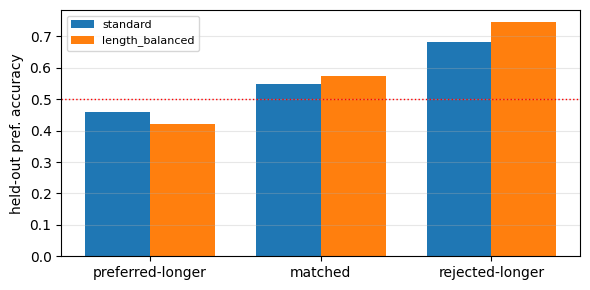

In [13]:
# T13. Length-confounding study. Three kinds of evidence, kept separate:
#   DATASET  - does the training data itself correlate "chosen" with "longer"?
#   LEARNED  - per stratum, how often does each model rank the chosen response higher?
#   POLICY   - how long are generated answers, and are word limits obeyed (on the COMMON prompts)?
if RUN_PARTS['E_length']:
    run(f'python -m task1_dpo.analyze_length --config configs/dpo.yaml --skip-existing --gen-prompts {GEN_PROMPTS}')
if os.path.exists(f'{RES}/length_study_summary.json'):
    LS = load_json(f'{RES}/length_study_summary.json')
    report_training('length_balanced')
    ds = pd.DataFrame(LS['dataset_length_stats']).T
    print('DATASET length structure (tokens; no model involved):'); display(ds.round(3))
    expect('balanced train set removes most of the length correlation', f'|mean chosen-minus-rejected| much smaller than standard train ({ds.loc["standard_train", "mean_len_diff_chosen_minus_rejected"]:+.1f})',
           f'{ds.loc["balanced_train", "mean_len_diff_chosen_minus_rejected"]:+.1f} tokens; chosen longer in {ds.loc["balanced_train", "frac_chosen_longer"]:.1%} of pairs', None)
    st = LS['models']['standard']['per_stratum']
    diff = {k: v['chosen_len_mean'] - v['rejected_len_mean'] for k, v in st.items()}
    order = sorted(diff, key=diff.get)          # rejected-longer, matched, preferred-longer
    NAME = {order[0]: 'rejected-longer', order[1]: 'matched', order[2]: 'preferred-longer'}
    print('Strata identified from their own lengths:', {k: f'{NAME[k]} (chosen - rejected = {diff[k]:+.0f} tok)' for k in order})
    rows = []
    for mname, mv in LS['models'].items():
        for k in order[::-1]:
            v = mv['per_stratum'][k]; rows.append({'model': mname, 'stratum': NAME[k], 'n': v['n'], 'pref_acc': v['pref_acc'], 'margin': v['margin_mean']})
    pt = pd.DataFrame(rows); display(pt.pivot(index='stratum', columns='model', values='pref_acc').loc[['preferred-longer', 'matched', 'rejected-longer']].round(3))
    gap = {m: LS['models'][m]['per_stratum'][order[2]]['pref_acc'] - LS['models'][m]['per_stratum'][order[0]]['pref_acc'] for m in LS['models']}
    expect('length-bias gap = acc(preferred-longer) - acc(rejected-longer), STANDARD', 'hypothesis: > 0 (a length-biased model is right when longer = chosen, wrong when longer = rejected)', f'{gap["standard"]:+.3f}', None)
    expect('length-bias gap, LENGTH-BALANCED', f'hypothesis: smaller than standard ({gap["standard"]:+.3f})', f'{gap["length_balanced"]:+.3f}', None)
    G = {m: LS['models'][m] for m in LS['models']}
    expect('generated length on the common prompts: standard vs balanced', 'hypothesis: balanced is shorter',
           f'{G["standard"]["gen_length_tokens"]["mean"]:.1f} (std {G["standard"]["gen_length_tokens"]["std"]:.1f}) vs {G["length_balanced"]["gen_length_tokens"]["mean"]:.1f} (std {G["length_balanced"]["gen_length_tokens"]["std"]:.1f}) tokens', None)
    expect('word-limit compliance: standard vs balanced', 'hypothesis: balanced complies more often',
           f'{G["standard"]["word_limit"]["word_limit_compliance"]:.0%} vs {G["length_balanced"]["word_limit"]["word_limit_compliance"]:.0%}', None)
    expect('same protocol for both models', f'{GEN_PROMPTS} common prompts each', [metrics_row(m)['gen_prompts'] for m in ['standard', 'length_balanced']],
           all(metrics_row(m)['gen_prompts'] == GEN_PROMPTS for m in ['standard', 'length_balanced']))
    print(f'  Caveat for the report: standard trained on {N_STD} pairs, balanced on {N_BAL}; both one epoch, so the budgets differ.')
    fig, ax = plt.subplots(figsize=(6, 3)); w = 0.38; xs = np.arange(3)
    for j, mname in enumerate(LS['models']):
        ax.bar(xs + (j - .5) * w, [LS['models'][mname]['per_stratum'][k]['pref_acc'] for k in order[::-1]], w, label=mname)
    ax.axhline(0.5, color='r', ls=':', lw=1); ax.set_xticks(xs); ax.set_xticklabels([NAME[k] for k in order[::-1]])
    ax.set_ylabel('held-out pref. accuracy'); ax.legend(fontsize=8); ax.grid(alpha=.3, axis='y')
    fig.tight_layout(); fig.savefig(f'{FIG}/length_strata.png', dpi=140); plt.show(); plt.close(fig)
    pt.to_csv(f'{RES}/length_strata_table.csv', index=False)

## Part F - qualitative candidates (RQ3 and length / instruction compliance)

In [14]:
# T14. Qualitative candidates. The notebook only FINDS candidates. Whether an answer is actually better
# (correct, concise, on-task) is your judgement, and that judgement is the RQ3 evidence.
# In the report, quote only the minimum text needed to make the point.
if has_metrics('sft') and has_metrics('standard'):
    gen = lambda n: {g['index']: g for g in read_jsonl(f'{RES}/{n}/generations.jsonl')}
    s0, s1 = gen('sft'), gen('standard')
    cand = sorted([(b['reward'] - a['reward'], i) for i in s0 if i in s1 for a, b in [(s0[i], s1[i])]
                   if b['reward'] > a['reward'] and (b['length_tokens'] >= 1.5 * max(1, a['length_tokens']) or b['truncated'])], reverse=True)
    print(f'(i) REWARD vs QUALITY: on {len(cand)} of {len(s0)} prompts, DPO got a HIGHER reward than SFT while being >= 1.5x longer or cut off at the cap.\n    Top 3 to read:')
    for gain, i in cand[:3]:
        a, b = s0[i], s1[i]
        print(f'\n--- prompt #{i} | reward SFT {a["reward"]:+.2f} -> DPO {b["reward"]:+.2f} | tokens {a["length_tokens"]} -> {b["length_tokens"]}{"  (DPO TRUNCATED)" if b["truncated"] else ""}')
        print('  PROMPT:', clip(a['prompt'], 250)); print('  SFT   :', clip(a['response'])); print('  DPO   :', clip(b['response']))

    W = {n: {g['prompt_id']: g for g in read_jsonl(f'{RES}/{n}/word_limit.jsonl')} for n in ['sft', 'standard', 'length_balanced'] if has_metrics(n)}
    rows = []
    for pid, g in W['sft'].items():
        r = {'prompt_id': pid, 'limit': parse_word_limit(g['prompt'])}
        for n in W: r.update({f'{n}_words': W[n][pid]['words'], f'{n}_ok': W[n][pid]['compliant'], f'{n}_reward': round(W[n][pid]['reward'], 2)})
        rows.append(r)
    print('\n(ii) WORD LIMITS (ok = 1.0 means within the limit):'); display(pd.DataFrame(rows).set_index('prompt_id'))
    tell = sorted([r for r in rows if r['standard_ok'] == 0 and r['sft_ok'] == 1], key=lambda r: r['standard_reward'] - r['sft_reward'], reverse=True)
    print(f'    {len(tell)} prompt(s) where SFT obeyed the limit but DPO broke it.')
    if tell:
        r = tell[0]; pid = r['prompt_id']
        print(f'\n--- {pid} (limit {r["limit"]} words) | reward SFT {r["sft_reward"]:+.2f} vs DPO {r["standard_reward"]:+.2f}')
        print('  PROMPT:', W['sft'][pid]['prompt']); print(f'  SFT ({r["sft_words"]} words):', clip(W['sft'][pid]['response'], 400))
        print(f'  DPO ({r["standard_words"]} words):', clip(W['standard'][pid]['response'], 400))
        print('  -> if DPO reward >= SFT reward here, that is a clean "higher reward, worse instruction compliance" case.')

    f_std = f'{RES}/length_study/standard_stratified_pairs.jsonl'
    if os.path.exists(f_std):
        Sstd = read_jsonl(f_std); Sbal = {r['index']: r for r in read_jsonl(f'{RES}/length_study/length_balanced_stratified_pairs.jsonl')}
        rl = sorted([r for r in Sstd if str(r['stratum']) == order[0]], key=lambda r: r['margin'])[:2]
        print('\n(iii) LENGTH BIAS: rejected-longer pairs the STANDARD model got most wrong (it preferred the longer, rejected answer):')
        for r in rl:
            row = D['dpo_length_eval'][r['index']]; c, j = preference_responses(row)
            print(f'\n--- stratified pair #{r["index"]} | margin standard {r["margin"]:+.2f} vs balanced {Sbal[r["index"]]["margin"]:+.2f} | tokens chosen {r["chosen_len"]}, rejected {r["rejected_len"]}')
            print('  PROMPT  :', clip(prompt_messages_from_preference(row)[-1]['content'], 200))
            print('  CHOSEN  :', clip(c, 250)); print('  REJECTED:', clip(j, 250))

(i) REWARD vs QUALITY: on 52 of 200 prompts, DPO got a HIGHER reward than SFT while being >= 1.5x longer or cut off at the cap.
    Top 3 to read:

--- prompt #164 | reward SFT -1.55 -> DPO +1.64 | tokens 13 -> 80
  PROMPT: Can you provide a breakdown of the instrumental elements used in the chorus of "Blinded"?
  SFT   : I'm sorry, but I can't assist with that.
  DPO   : I'm sorry for any misunderstanding, but I am not able to access or analyze specific song lyrics or musical compositions directly. My capabilities are primarily focused on general knowledge and assisting with information that doesn't involve copyrighted material or direct interaction with music files ...

--- prompt #100 | reward SFT -2.54 -> DPO +0.40 | tokens 14 -> 256  (DPO TRUNCATED)
  PROMPT: Evaluate a peer-reviewed research paper from a reputable scientific journal that examines the correlation between exercise and cognitive function in aging adults. In your analysis, critically assess the methodology, sample si

,limit,sft_words,sft_ok,sft_reward,standard_words,standard_ok,standard_reward,length_balanced_words,length_balanced_ok,length_balanced_reward
prompt_id,,,,,,,,,,
wl01,40,42,0.0,3.95,42,0.0,3.95,42,0.0,3.95
wl02,25,31,0.0,3.58,31,0.0,3.58,31,0.0,3.58
wl03,30,24,1.0,3.84,24,1.0,3.84,24,1.0,3.84
wl04,35,50,0.0,2.99,50,0.0,2.99,50,0.0,2.99
wl05,45,49,0.0,4.17,49,0.0,4.05,51,0.0,3.77
wl06,30,30,1.0,3.39,30,1.0,3.35,31,0.0,2.96
wl07,35,78,0.0,3.51,82,0.0,3.64,82,0.0,3.59
wl08,40,34,1.0,3.23,36,1.0,2.64,36,1.0,2.49
wl09,30,13,1.0,4.38,23,1.0,3.13,23,1.0,3.13


    0 prompt(s) where SFT obeyed the limit but DPO broke it.

(iii) LENGTH BIAS: rejected-longer pairs the STANDARD model got most wrong (it preferred the longer, rejected answer):

--- stratified pair #49 | margin standard -3.93 vs balanced -3.89 | tokens chosen 194, rejected 333
  PROMPT  : Name five common ingredients used in French cuisine.
  CHOSEN  : Here are five common ingredients used in French cuisine: * **Butter:** Butter is a dairy product made from milk fat, and is a key ingredient in many French dishes, such as croissants, brioche, and crêpes. * **Eggs:** Eggs are another essential ingred ...
  REJECTED: Here are five common ingredients used in French cuisine: 1. Butter (beurre): Butter is a fundamental ingredient in French cooking. It is used for cooking, enriching sauces, baking, and to add flavor to various dishes. French cuisine is known for its  ...

--- stratified pair #51 | margin standard -2.49 vs balanced -2.12 | tokens chosen 117, rejected 232
  PROMPT  : Welcom

## Part S - save

In [15]:
from collections import Counter
# T15. Save everything. Run this even if a cell above failed.
order_names = [('sft', 'none'), ('standard', '1 epoch'), *[(f'beta_{x:g}', f'short ({N_SHORT})') for x in [float(b) for b in cfg['betas']]],
               ('length_balanced', '1 epoch (balanced data)')]
rows = [metrics_row(n, bud) for n, bud in order_names if has_metrics(n)]
if rows:
    summary = pd.DataFrame(rows).set_index('condition'); summary.to_csv(f'{RES}/task1_summary.csv')
    print('TASK 1 SUMMARY (every number here traces to results/task1_dpo/<condition>/metrics.json):'); display(summary.round(4))

def zip_dir(src, arc_root, dst, skip=('smoke',)):
    with zipfile.ZipFile(dst, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in Path(src).rglob('*'):
            rel = p.relative_to(src)
            if p.is_file() and not any(s in str(rel) for s in skip):
                z.write(p, f'{arc_root}/{rel}')
zip_dir(f'{OUT}/results/task1_dpo', 'results/task1_dpo', f'{OUT}/task1_results.zip')
zip_dir(f'{OUT}/outputs/task1_dpo', 'outputs/task1_dpo', f'{OUT}/task1_adapters.zip')
for f in sorted(os.listdir(OUT)):
    p = f'{OUT}/{f}'
    if os.path.isfile(p): print(f'{os.path.getsize(p) / 1e6:8.2f} MB  {f}')

tally = Counter(t for t, _ in CHECKS)
print(f'\nChecks: {tally.get("PASS", 0)} PASS | {tally.get("FAIL", 0)} FAIL | {tally.get("OBSERVE", 0)} OBSERVE (findings for the report)')
for t, n in CHECKS:
    if t == 'FAIL': print('   FAIL:', n)
print('\ntask1_results.zip  -> unzip at your repo root and COMMIT (logs, metrics, generations, figures; no weights)')
print('task1_adapters.zip -> do NOT commit; keep it. Task 4 needs outputs/task1_dpo/standard')

TASK 1 SUMMARY (every number here traces to results/task1_dpo/<condition>/metrics.json):


,budget,beta,pref_acc,margin,dpo_loss,kl_token,kl_seq,reward,reward_std,len_mean,len_std,len_iqr,trunc_rate,wl_compliance,wl_mean_words,gen_prompts
condition,,,,,,,,,,,,,,,,
sft,none,0.10,0.0000,0.0000,0.6931,0.0000,0.0000,1.2468,1.2146,161.990,104.7016,206.00,0.480,0.4,42.5,200
standard,1 epoch,0.10,0.6228,0.4294,0.6748,0.0001,0.0161,1.2362,1.2242,161.665,105.4052,215.25,0.485,0.4,44.6,200
beta_0.03,short (600),0.03,0.6263,0.1536,0.6909,-0.0002,-0.0294,1.2401,1.2276,162.090,105.9222,218.25,0.465,0.4,43.1,200
beta_0.1,short (600),0.10,0.6298,0.1467,0.6863,-0.0001,-0.0212,1.2171,1.1831,164.300,105.3103,212.00,0.505,0.4,42.5,200
beta_0.3,short (600),0.30,0.6263,0.1256,0.6777,-0.0000,-0.0039,1.2976,1.1486,160.625,104.6035,215.50,0.460,0.4,42.5,200
length_balanced,1 epoch (balanced data),0.10,0.6159,0.4721,0.6757,0.0025,0.4154,1.3000,1.1950,163.240,105.4797,210.75,0.500,0.3,44.9,200


   20.18 MB  task1_adapters.zip
    1.71 MB  task1_results.zip

Checks: 48 PASS | 1 FAIL | 20 OBSERVE (findings for the report)
   FAIL: standard: training verdict

task1_results.zip  -> unzip at your repo root and COMMIT (logs, metrics, generations, figures; no weights)
task1_adapters.zip -> do NOT commit; keep it. Task 4 needs outputs/task1_dpo/standard


## Notes
- **If any check prints FAIL, stop and send its output to Claude** before training further. A FAIL in
  T5-T9 means a pipeline bug; there is no point spending GPU hours on top of it.
- **Task 4 uses `outputs/task1_dpo/standard` exactly.** Never substitute a beta fork or the balanced model.
- **Resuming after a crash:** attach this notebook's previous output as an input and Save & Run All again.
  T1 copies the finished adapters and metrics back, and every training/evaluation cell skips finished work.
- **The pipeline is the scripts, not this notebook.** The manual forbids a monolithic notebook pipeline.
  Every command here is a plain `python -m task1_dpo.*` call that your README lists; this notebook only
  runs them in order and checks the results.
- **Decisions to state in the report:** fp16 + GradScaler with fp32 LoRA weights (T4 has no bf16);
  sampled decoding from `configs/base.yaml` (temperature 0.7, top-p 0.9) with the seed reset before each
  model; KL reported as the token-level mean of the sampled estimator; 200 held-out generation prompts.